# CSCI461 – Assignment 1: Dockerized Data, Text Analysis and Machine Learning
## Dataset: SMS Spam Collection (UCI #228)

**Pipeline:** Dockerfile → custom image → container → JupyterLab → data cleaning → sampling → text analysis → TF‑IDF → classification + K‑Means → persistent outputs (`output/`, bind‑mounted to the host).

| Section | Content |
|---|---|
| 0 | Environment check (proves the notebook runs inside the container) |
| 4 | Data understanding, missing values & duplicates, `loc`/`iloc`, transformations, sampling, correlation |
| 5 | Text cleaning, tokenisation, word frequencies, spam vs ham comparison, insights |
| 6 | Supervised TF‑IDF classification (2 classifiers + tuned n‑gram model = bonus) and K‑Means clustering |
| 7 | Saved outputs checklist |

Run with **Kernel → Restart Kernel and Run All Cells**. Every random step uses `random_state=42`, so results are reproducible.

## 0. Setup and environment check

In [1]:
import os, re, sys, html, string, platform, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, Normalizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, silhouette_score,
                             adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Project root: works whether Jupyter starts in bd-a1/ or in bd-a1/notebook/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "dataset.csv"
OUTPUT_DIR = ROOT / "output"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(ROOT)}")

in_docker = Path("/.dockerenv").exists() or os.environ.get("JUPYTER_DOCKER_STACKS_FOLDER") is not None \
            or os.environ.get("NB_USER") == "jovyan"
print("Running inside Docker container:", in_docker)
print("Hostname      :", platform.node())
print("Python        :", sys.version.split()[0])
print("pandas        :", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("Project root  :", ROOT)
print("Dataset path  :", DATA_PATH, "| exists:", DATA_PATH.exists())

Running inside Docker container: False
Hostname      : vm
Python        : 3.13.18
pandas        : 3.0.5 | numpy: 2.5.3 | scikit-learn: 1.9.1
Project root  : /home/claude/bd-a1
Dataset path  : /home/claude/bd-a1/data/dataset.csv | exists: True


## 4. Data Analysis and Preprocessing
### 4.1 Dataset understanding
The original UCI file (`SMSSpamCollection`) is tab‑separated with no header. It was converted once on the host into `data/dataset.csv` with two columns, `label` and `message` (see README for the exact command).

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")
df = df_raw.copy()
display(df.head(10))

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"
5,spam,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv"
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030


In [3]:
print("Shape  :", df.shape)
print("Columns:", list(df.columns))
print("\nData types:\n", df.dtypes, sep="")
print()
df.info()

Shape  : (5574, 2)
Columns: ['label', 'message']

Data types:
label      str
message    str
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5574 non-null   str  
 1   message  5574 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


In [4]:
display(df.describe(include="all"))
print("\nClass distribution:")
display(pd.DataFrame({"count": df["label"].value_counts(),
                      "percent": df["label"].value_counts(normalize=True).mul(100).round(2)}))

,label,message
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30



Class distribution:


,count,percent
label,,
ham,4827,86.6
spam,747,13.4


**What one row represents:** one SMS text message received on a mobile phone, together with a human‑assigned label saying whether it is legitimate (`ham`) or unsolicited advertising/scam (`spam`).

| Column type | Column(s) | Notes |
|---|---|---|
| **Text** | `message` | Raw SMS body (free text, slang, abbreviations, numbers, URLs) |
| **Label / category** | `label` | Binary target: `ham` (≈86.6 %) vs `spam` (≈13.4 %) → **imbalanced** |
| **Numerical** | *none in the raw file* | Numerical columns are **engineered** from the text in 4.4 (character count, word count, digit count, …) and used for correlation and normalisation |

`describe()` already shows that the most frequent message ("Sorry, I'll call later") occurs many times, a first hint of duplicates.

### 4.2 Missing values and duplicates

In [5]:
print("Missing values per column:")
display(df.isna().sum().to_frame("missing"))

empty_msgs = df["message"].fillna("").str.strip().eq("").sum()
print("Empty / whitespace-only messages:", empty_msgs)

dup_rows = df.duplicated().sum()
dup_msgs = df["message"].duplicated().sum()
conflicts = (df.groupby("message")["label"].nunique() > 1).sum()
print("Exact duplicate rows (label + message):", dup_rows)
print("Duplicate message texts              :", dup_msgs)
print("Same text with different labels      :", conflicts)

print("\nDuplicate rows by class:")
display(df[df.duplicated()]["label"].value_counts().to_frame("duplicates"))
print("Most repeated messages:")
display(df["message"].value_counts().head(5).to_frame("times"))

Missing values per column:


,missing
label,0
message,0


Empty / whitespace-only messages: 0
Exact duplicate rows (label + message): 403
Duplicate message texts              : 403
Same text with different labels      : 0

Duplicate rows by class:


,duplicates
label,
ham,309
spam,94


Most repeated messages:


,times
message,
"Sorry, I'll call later",30
I cant pick the phone right now. Pls send a message,12
Ok...,10
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!,4
"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.",4


**Treatment and justification**

* **Missing values:** there are none (and no empty strings). A defensive `fillna("")` is still applied in the text‑cleaning function so the pipeline cannot break on future data.
* **Duplicates:** the exact duplicates are **removed** (keeping the first occurrence) because
  1. repeated spam templates and chain messages would be **over‑counted** in word frequencies and group statistics;
  2. if the same message appears in both the training and the test split, the classifier is tested on text it has **already seen** (data leakage), which inflates accuracy;
  3. no duplicate text carries conflicting labels, so dropping copies loses no information.

In [6]:
shape_before = df.shape
df = df.drop_duplicates(keep="first").reset_index(drop=True)
shape_after = df.shape
print(f"Shape before cleaning: {shape_before}")
print(f"Shape after cleaning : {shape_after}  ({shape_before[0] - shape_after[0]} rows removed)")
display(pd.DataFrame({"before": df_raw["label"].value_counts(), "after": df["label"].value_counts()}))

Shape before cleaning: (5574, 2)
Shape after cleaning : (5171, 2)  (403 rows removed)


,before,after
label,,
ham,4827,4518
spam,747,653


### 4.3 Selection with `loc` and `iloc`
* `loc` selects by **label / boolean condition**.
* `iloc` selects by **integer position**; `np.r_` concatenates several position ranges into one indexer.

In [7]:
# loc: meaningful conditional selection -> spam messages that mention "free" and are longer than 120 characters
mask = (df["label"] == "spam") & df["message"].str.contains(r"\bfree\b", case=False) & (df["message"].str.len() > 120)
free_spam = df.loc[mask, ["label", "message"]]
print(f"Long spam messages containing 'free': {len(free_spam)} rows")
display(free_spam.head(5))

Long spam messages containing 'free': 128 rows


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C www.dbuk.net LCCLTD POBOX 4403LDNW1A7RW18"
42,spam,07732584351 - Rodger Burns - MSG = We tried to call you re your reply to our sms for a free nokia mobile + free camcorder. Please call now 08000930705 for delivery tomorrow
56,spam,"Congrats! 1 year special cinema pass for 2 is yours. call 09061209465 now! C Suprman V, Matrix3, StarWars3, etc all 4 FREE! bx420-ip4-5we. 150pm. Dont miss out!"


In [8]:
# iloc: plain positional selection -> rows 10-14, both columns
display(df.iloc[10:15, 0:2])

# iloc + np.r_: first 3 rows, rows 2000-2002 and the last 3 rows in a single selection
display(df.iloc[np.r_[0:3, 2000:2003, -3:0], :])

,label,message
10,ham,"I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today."
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info"
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C www.dbuk.net LCCLTD POBOX 4403LDNW1A7RW18"
13,ham,I've been searching for the right words to thank you for this breather. I promise i wont take your help for granted and will fulfil my promise. You have been wonderful and a blessing at all times.
14,ham,I HAVE A DATE ON SUNDAY WITH WILL!!


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
2000,ham,Must come later.. I normally bathe him in da afternoon mah..
2001,ham,"Trust me. Even if isn't there, its there."
2002,ham,Hey hun-onbus goin 2 meet him. He wants 2go out 4a meal but I donyt feel like it cuz have 2 get last bus home!But hes sweet latelyxxx
5168,ham,"Pity, * was in mood for that. So...any other suggestions?"
5169,ham,The guy did some bitching but I acted like i'd be interested in buying something else next week and he gave it to us for free
5170,ham,Rofl. Its true to its name


### 4.4 Transformations and feature creation
Five transformations are applied:

| # | Type | Result |
|---|---|---|
| T1 | **Type conversion** | `label` → `category`, `message` → `string` |
| T2 | **Encoding** | `label_num`: ham = 0, spam = 1 (needed by models and correlation) |
| T3 | **Feature creation** | numerical text features: `char_count`, `word_count`, `unique_word_count`, `avg_word_length`, `digit_count`, `uppercase_ratio`, `punctuation_count`, `exclamation_count`, `has_url`, `has_long_number` |
| T4 | **Binning** | `length_bin` based on the 160‑character limit of a single SMS |
| T5 | **Normalisation** | Min–Max scaling of the numerical features into [0, 1] (`*_norm` columns) |

In [9]:
# T1 - type conversion
print("Before:", df.dtypes.to_dict())
df["label"] = df["label"].astype("category")
df["message"] = df["message"].astype("string")
print("After :", df.dtypes.to_dict())

# T2 - label encoding
df["label_num"] = df["label"].map({"ham": 0, "spam": 1}).astype(int)
display(df[["label", "label_num"]].drop_duplicates())

Before: {'label': <StringDtype(storage='python', na_value=nan)>, 'message': <StringDtype(storage='python', na_value=nan)>}
After : {'label': CategoricalDtype(categories=['ham', 'spam'], ordered=False, categories_dtype=str), 'message': <StringDtype(storage='python', na_value=<NA>)>}


,label,label_num
0,ham,0
2,spam,1


In [10]:
# T3 - numerical feature creation from the ORIGINAL message (HTML entities such as &lt; decoded first)
raw_text = df["message"].fillna("").astype(str).map(html.unescape)
words = raw_text.str.split()

df["char_count"]        = raw_text.str.len()
df["word_count"]        = words.str.len()
df["unique_word_count"] = words.map(lambda w: len({x.lower() for x in w}))
df["avg_word_length"]   = words.map(lambda w: np.mean([len(x) for x in w]) if w else 0.0).round(3)
df["digit_count"]       = raw_text.str.count(r"\d")
df["uppercase_ratio"]   = (raw_text.str.count(r"[A-Z]") / df["char_count"].clip(lower=1)).round(4)
df["punctuation_count"] = raw_text.map(lambda t: sum(ch in string.punctuation for ch in t))
df["exclamation_count"] = raw_text.str.count("!")
df["has_url"]           = raw_text.str.contains(r"https?://|www\.|\.com\b|\.co\.uk\b", case=False).astype(int)
df["has_long_number"]   = raw_text.str.contains(r"\d{5,}").astype(int)   # phone / short-code numbers

NUM_FEATURES = ["char_count", "word_count", "unique_word_count", "avg_word_length",
                "digit_count", "uppercase_ratio", "punctuation_count", "exclamation_count"]
display(df[["label"] + NUM_FEATURES].head())

,label,char_count,word_count,unique_word_count,avg_word_length,digit_count,uppercase_ratio,punctuation_count,exclamation_count
0,ham,111,20,20,4.600,0,0.0270,9,0
1,ham,29,6,6,4.000,0,0.0690,6,0
2,spam,155,28,24,4.571,25,0.0645,6,0
3,ham,49,11,10,3.545,0,0.0408,6,0
4,ham,61,13,12,3.769,0,0.0328,2,0


In [11]:
# T4 - binning: 160 characters is the length limit of one SMS
bins   = [0, 50, 100, 160, np.inf]
labels = ["short (<=50)", "medium (51-100)", "long (101-160)", "multi-part (>160)"]
df["length_bin"] = pd.cut(df["char_count"], bins=bins, labels=labels)

display(pd.crosstab(df["length_bin"], df["label"], margins=True))
display(pd.crosstab(df["length_bin"], df["label"], normalize="index").mul(100).round(1)
          .rename(columns=lambda c: f"% {c}"))

label,ham,spam,All
length_bin,,,
short (<=50),2171,20,2191
medium (51-100),1351,53,1404
long (101-160),817,527,1344
multi-part (>160),179,53,232
All,4518,653,5171


label,% ham,% spam
length_bin,,
short (<=50),99.1,0.9
medium (51-100),96.2,3.8
long (101-160),60.8,39.2
multi-part (>160),77.2,22.8


In [12]:
# T5 - Min-Max normalisation of the numerical features
scaler = MinMaxScaler()
norm_cols = [f"{c}_norm" for c in NUM_FEATURES]
df[norm_cols] = scaler.fit_transform(df[NUM_FEATURES])

comparison = pd.concat({"original": df[NUM_FEATURES[:4]].describe().loc[["min", "max", "mean"]],
                        "normalised": df[norm_cols[:4]].describe().loc[["min", "max", "mean"]]}, axis=1)
display(comparison.round(3))

original                                                   normalised                                                            
     char_count word_count unique_word_count avg_word_length char_count_norm word_count_norm unique_word_count_norm avg_word_length_norm
min       2.000      1.000             1.000           1.500           0.000           0.000                  0.000                0.000
max     910.000    171.000           100.000          49.000           1.000           1.000                  1.000                1.000
mean     78.955     15.434            14.266           4.227           0.085           0.085                  0.134                0.057

Saved figure -> output/figures/length_distribution.png


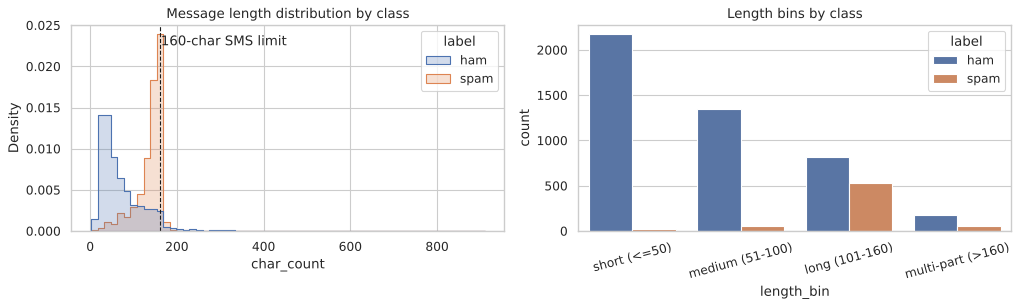

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="char_count", hue="label", bins=60, stat="density", common_norm=False,
             element="step", ax=axes[0])
axes[0].axvline(160, color="k", ls="--", lw=1); axes[0].text(163, axes[0].get_ylim()[1]*0.9, "160-char SMS limit")
axes[0].set_title("Message length distribution by class")
sns.countplot(data=df, x="length_bin", hue="label", ax=axes[1])
axes[1].set_title("Length bins by class"); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); save_fig(fig, "length_distribution.png"); plt.show()

### 4.5 Sampling: simple random, stratified and cluster
Each sample is ≈20 % of the cleaned data.

* **Simple random sampling (SRS):** every message has the same chance of being chosen, independently.
* **Stratified sampling:** the data is split into strata by `label`, and 20 % is drawn **from each stratum** so the class proportions are preserved exactly.
* **Cluster sampling:** the data is divided into **clusters** (here: consecutive blocks of 100 messages, like batches received by a telecom server), then **whole clusters** are randomly selected and all their messages kept. The README of the dataset states the messages are *not chronologically sorted*, so blocks are reasonable clusters.

In [14]:
FRAC = 0.20
srs = df.sample(frac=FRAC, random_state=RANDOM_STATE)

stratified = df.groupby("label", group_keys=False, observed=True).sample(frac=FRAC, random_state=RANDOM_STATE)

CLUSTER_SIZE = 100
df["cluster_block"] = np.arange(len(df)) // CLUSTER_SIZE
n_blocks = df["cluster_block"].nunique()
rng = np.random.default_rng(RANDOM_STATE)
chosen_blocks = rng.choice(n_blocks, size=round(FRAC * n_blocks), replace=False)
cluster_sample = df[df["cluster_block"].isin(chosen_blocks)]
print(f"{n_blocks} clusters of {CLUSTER_SIZE} messages; selected clusters: {sorted(chosen_blocks.tolist())}")

def dist(d):
    vc = d["label"].value_counts()
    return pd.Series({"n": len(d), "ham": vc.get("ham", 0), "spam": vc.get("spam", 0),
                      "% ham": round(100 * vc.get("ham", 0) / len(d), 2),
                      "% spam": round(100 * vc.get("spam", 0) / len(d), 2)})

sampling_table = pd.DataFrame({"Original (clean)": dist(df), "Simple random": dist(srs),
                               "Stratified": dist(stratified), "Cluster": dist(cluster_sample)}).T
display(sampling_table)

52 clusters of 100 messages; selected clusters: [3, 4, 10, 20, 29, 34, 41, 46, 49, 51]


,n,ham,spam,% ham,% spam
Original (clean),5171.0,4518.0,653.0,87.37,12.63
Simple random,1034.0,897.0,137.0,86.75,13.25
Stratified,1035.0,904.0,131.0,87.34,12.66
Cluster,971.0,866.0,105.0,89.19,10.81


True % spam in cleaned data: 12.628


,mean,std,min,max
Simple random,12.630,0.907,10.542,14.990
Stratified,12.657,0.000,12.657,12.657
Cluster,12.534,0.965,10.100,15.400


Saved figure -> output/figures/sampling_comparison.png


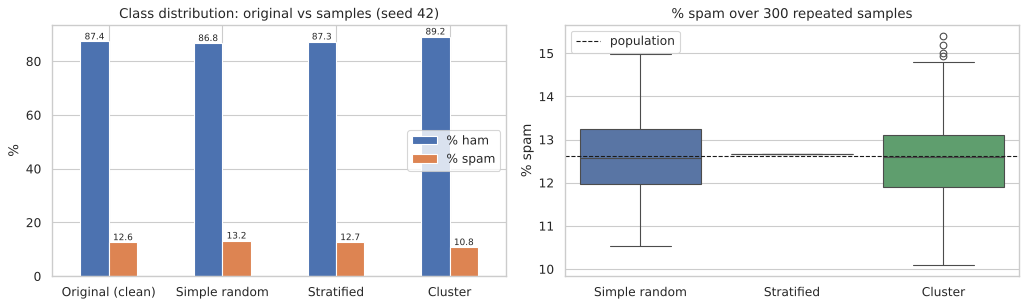

In [15]:
# How stable is each method? Repeat each 300 times with different seeds and look at the spread of % spam.
def spam_pct(d): return 100 * (d["label"] == "spam").mean()
reps = {"Simple random": [], "Stratified": [], "Cluster": []}
for seed in range(300):
    reps["Simple random"].append(spam_pct(df.sample(frac=FRAC, random_state=seed)))
    reps["Stratified"].append(spam_pct(df.groupby("label", group_keys=False, observed=True).sample(frac=FRAC, random_state=seed)))
    blocks = np.random.default_rng(seed).choice(n_blocks, size=round(FRAC * n_blocks), replace=False)
    reps["Cluster"].append(spam_pct(df[df["cluster_block"].isin(blocks)]))
rep_df = pd.DataFrame(reps)
stability = rep_df.agg(["mean", "std", "min", "max"]).T.round(3)
print(f"True % spam in cleaned data: {spam_pct(df):.3f}")
display(stability)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_tbl = sampling_table[["% ham", "% spam"]]
plot_tbl.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0)
axes[0].set_title("Class distribution: original vs samples (seed 42)"); axes[0].set_ylabel("%")
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.1f", fontsize=8)
sns.boxplot(data=rep_df, ax=axes[1]); axes[1].axhline(spam_pct(df), color="k", ls="--", lw=1, label="population")
axes[1].set_title("% spam over 300 repeated samples"); axes[1].set_ylabel("% spam"); axes[1].legend()
plt.tight_layout(); save_fig(fig, "sampling_comparison.png"); plt.show()

**Comparison of the three methods**

* **Stratified** reproduces the original class ratio (almost) exactly every time; its spread across 300 repetitions is practically zero. It is the right choice when a minority class (spam) must be represented faithfully, which is why the train/test split in Section 6 is stratified.
* **Simple random** is unbiased on average, but any single sample can drift by roughly ±1 percentage point in % spam, purely by chance.
* **Cluster** sampling is the cheapest to collect (take whole batches), but it has the **largest variance**: messages inside a block are not perfectly mixed, so choosing a few blocks can over‑ or under‑represent spam. The sample size is also fixed by the cluster sizes rather than chosen exactly.

### 4.6 Correlation of numerical text features

Saved figure -> output/figures/correlation_heatmap.png


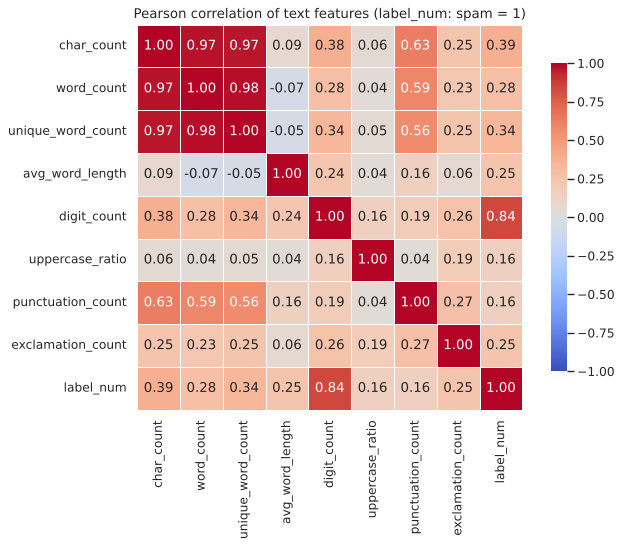

Strongest relationships:


,feature_1,feature_2,r,|r|
11,word_count,unique_word_count,0.981,0.981
1,char_count,word_count,0.974,0.974
2,char_count,unique_word_count,0.966,0.966
44,digit_count,label_num,0.837,0.837
6,char_count,punctuation_count,0.625,0.625
15,word_count,punctuation_count,0.592,0.592


Weakest relationships:


,feature_1,feature_2,r,|r|
14,word_count,uppercase_ratio,0.037,0.037
51,uppercase_ratio,punctuation_count,0.039,0.039
32,avg_word_length,uppercase_ratio,0.044,0.044
23,unique_word_count,uppercase_ratio,0.047,0.047


Correlation of each feature with spam (label_num):


,r with spam
digit_count,0.837
char_count,0.386
unique_word_count,0.337
word_count,0.284
exclamation_count,0.255
avg_word_length,0.250
punctuation_count,0.159
uppercase_ratio,0.159


In [16]:
corr_cols = NUM_FEATURES + ["label_num"]
corr = df[corr_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Pearson correlation of text features (label_num: spam = 1)")
plt.tight_layout(); save_fig(fig, "correlation_heatmap.png"); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("r").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["|r|"] = pairs["r"].abs()
print("Strongest relationships:"); display(pairs.sort_values("|r|", ascending=False).head(6).round(3))
print("Weakest relationships:");   display(pairs.sort_values("|r|").head(4).round(3))
print("Correlation of each feature with spam (label_num):")
display(corr["label_num"].drop("label_num").sort_values(ascending=False).round(3).to_frame("r with spam"))

**Interpretation** *(values from the heatmap above)*

* **Very strong (r ≈ 0.97–0.98):** `word_count`, `unique_word_count` and `char_count` move almost perfectly together. They are mechanically linked (more words means more characters), so they carry nearly the same information. Using all three in a linear model would be redundant (multicollinearity).
* **Strong link with the target:** `digit_count` has **r = 0.84 with spam**, by far the highest. Spam is full of phone numbers, prices and short codes.
* **Moderate:** `char_count` with spam (r ≈ 0.39): spam is longer on average, but many ham messages are long too. `char_count` with `punctuation_count` (r ≈ 0.63): longer texts simply contain more punctuation.
* **Weak / none:** `uppercase_ratio` is almost uncorrelated with the length features (|r| ≈ 0.04) and only weakly with spam (r ≈ 0.16). Shouting in capitals happens in both classes ("I HAVE A DATE ON SUNDAY WITH WILL!!"). `exclamation_count` is weakly related to spam (r ≈ 0.26).


**Why correlation does not imply causation:** a correlation only says two variables move together. For example, `digit_count` is strongly associated with spam, but adding digits to a message does not *make* it spam. Both are driven by a third factor: commercial senders who include phone numbers, prices and short codes. Correlation also only measures *linear* association, can be inflated by outliers and by features that are mechanically derived from each other (word count is part of character count), and says nothing about direction. Establishing cause requires controlled experiments or causal reasoning, not a coefficient.

## 5. Text Analysis
### 5.1 Cleaning → new column `cleaned_text` (original `message` kept unchanged)

Steps, in order:
1. handle missing text (`NaN` → `""`);
2. decode HTML entities (`&lt;` → `<`, `&amp;` → `&`) and **remove the anonymisation placeholders** used in this corpus (`<#>`, `<DECIMAL>`, `<URL>`, `<TIME>`, `<EMAIL>`);
3. lowercase;
4. replace URLs with `urltoken`, currency symbols (£ $ €) with `moneytoken`, numbers of ≥5 digits (phone numbers / short codes) with `phonetoken`, and other numbers with `numtoken`. In spam, *the presence* of a number matters more than its exact value;
5. remove apostrophes (`don't` → `dont`), then all remaining punctuation and non‑letters;
6. collapse repeated whitespace.

In [17]:
PLACEHOLDER_RE = re.compile(r"<\s*(?:#|decimal|url|time|email)\s*>", re.IGNORECASE)
URL_RE   = re.compile(r"(https?://\S+|www\.\S+|\b[a-z0-9-]+\.(?:com|co\.uk|net|org|biz|tv|us)\b\S*)")
MONEY_RE = re.compile(r"[£$€]")
PHONE_RE = re.compile(r"(?<!\d)\d{5,}(?!\d)")
NUM_RE   = re.compile(r"\d+")

def clean_text(text):
    if pd.isna(text):
        return ""
    t = html.unescape(str(text))
    t = PLACEHOLDER_RE.sub(" ", t)
    t = t.lower()
    t = URL_RE.sub(" urltoken ", t)
    t = MONEY_RE.sub(" moneytoken ", t)
    t = PHONE_RE.sub(" phonetoken ", t)
    t = NUM_RE.sub(" numtoken ", t)
    t = re.sub(r"['’‘`]", "", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["cleaned_text"] = df["message"].map(clean_text)
display(df.loc[[0, 2, 8, 15, 44], ["message", "cleaned_text"]])
print("Messages that became empty after cleaning:", (df["cleaned_text"] == "").sum())

,message,cleaned_text
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,free entry in numtoken a wkly comp to win fa cup final tkts numtoken st may numtoken text fa to phonetoken to receive entry question std txt rate t cs apply phonetoken over numtoken s
8,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.,winner as a valued network customer you have been selected to receivea moneytoken numtoken prize reward to claim call phonetoken claim code kl numtoken valid numtoken hours only
15,"XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmobilemovieclub.com?n=QJKGIGHJJGCBL",xxxmobilemovieclub to use your credit click the wap link in the next txt message or click here urltoken urltoken
44,Great! I hope you like your man well endowed. I am &lt;#&gt; inches...,great i hope you like your man well endowed i am inches


Messages that became empty after cleaning: 2


### 5.2 Tokenisation

In [18]:
df["tokens"] = df["cleaned_text"].str.split()
df["token_count"] = df["tokens"].str.len()

all_tokens = [tok for toks in df["tokens"] for tok in toks]
total_tokens = len(all_tokens)
unique_words = len(set(all_tokens))
avg_words = df["token_count"].mean()

print(f"Total tokens            : {total_tokens:,}")
print(f"Unique words (vocabulary): {unique_words:,}")
print(f"Average words per record : {avg_words:.2f}")

Total tokens            : 81,898
Unique words (vocabulary): 7,785
Average words per record : 15.84


### 5.3 20 most frequent words (before and after stop‑word removal)
Stop words = scikit‑learn's English list plus SMS‑specific fillers (`u`, `ur`, `im`, `lor`, `da`, single letters…). The special tokens (`numtoken`, `phonetoken`, …) are **kept** because they are informative.

In [19]:
SMS_FILLERS = {"u", "ur", "im", "r", "n", "s", "d", "k", "m", "t", "ll", "ve", "re", "dont", "didnt",
               "cant", "wont", "ill", "ive", "id", "youre", "thats", "lor", "da", "la", "lar", "wat", "oh"}
STOPWORDS = set(ENGLISH_STOP_WORDS) | SMS_FILLERS

freq_all = Counter(all_tokens)
freq_nostop = Counter(t for t in all_tokens if t not in STOPWORDS)

top20 = pd.DataFrame({
    "rank": range(1, 21),
    "word (all)": [w for w, _ in freq_all.most_common(20)],
    "count (all)": [c for _, c in freq_all.most_common(20)],
    "word (no stop words)": [w for w, _ in freq_nostop.most_common(20)],
    "count (no stop words)": [c for _, c in freq_nostop.most_common(20)],
}).set_index("rank")
display(top20)
share = sum(c for w, c in freq_all.most_common(20) if w in STOPWORDS) / sum(c for _, c in freq_all.most_common(20))
print(f"Stop words make up {share:.0%} of the top-20 occurrences before removal.")

,word (all),count (all),word (no stop words),count (no stop words)
rank,,,,
1,numtoken,3269,numtoken,3269
2,i,2256,phonetoken,647
3,to,2080,just,350
4,you,2060,moneytoken,295
5,a,1325,ok,261
6,the,1249,free,253
7,u,1071,know,244
8,and,930,like,236
9,in,835,got,234


Stop words make up 82% of the top-20 occurrences before removal.


Saved figure -> output/figures/word_frequency_top20.png


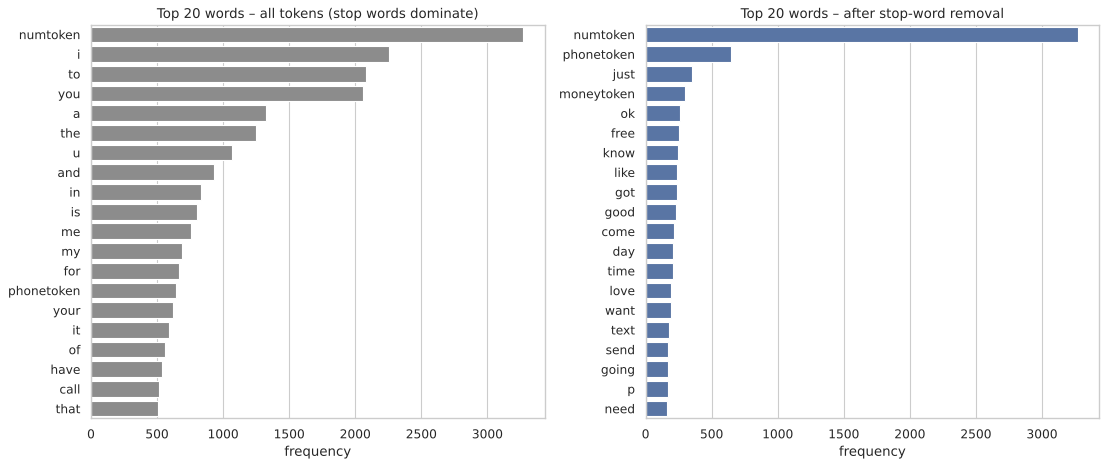

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=top20["count (all)"], y=top20["word (all)"], ax=axes[0], color="#8c8c8c")
axes[0].set_title("Top 20 words – all tokens (stop words dominate)")
sns.barplot(x=top20["count (no stop words)"], y=top20["word (no stop words)"], ax=axes[1], color="#4C72B0")
axes[1].set_title("Top 20 words – after stop-word removal")
for ax in axes: ax.set_xlabel("frequency"); ax.set_ylabel("")
plt.tight_layout(); save_fig(fig, "word_frequency_top20.png"); plt.show()

### 5.4 Group comparison: spam vs ham

In [21]:
df["tokens_nostop"] = df["tokens"].map(lambda ts: [t for t in ts if t not in STOPWORDS])

group_stats = df.groupby("label", observed=True).agg(
    messages=("message", "size"),
    avg_char_length=("char_count", "mean"),
    avg_word_count=("word_count", "mean"),
    avg_unique_words=("unique_word_count", "mean"),
    avg_digits=("digit_count", "mean"),
    pct_with_long_number=("has_long_number", lambda s: 100 * s.mean()),
    pct_with_url=("has_url", lambda s: 100 * s.mean()),
    avg_exclamations=("exclamation_count", "mean"),
).round(2)
display(group_stats)

top10 = {}
for lab in ["ham", "spam"]:
    cnt = Counter(t for ts in df.loc[df["label"] == lab, "tokens_nostop"] for t in ts)
    top10[lab] = cnt.most_common(10)
top10_df = pd.DataFrame({f"{lab} word": [w for w, _ in top10[lab]] for lab in top10} |
                        {f"{lab} count": [c for _, c in top10[lab]] for lab in top10},
                        index=range(1, 11))[["ham word", "ham count", "spam word", "spam count"]]
display(top10_df)

,messages,avg_char_length,avg_word_count,avg_unique_words,avg_digits,pct_with_long_number,pct_with_url,avg_exclamations
label,,,,,,,,
ham,4518,70.46,14.23,13.1,0.30,0.07,0.22,0.18
spam,653,137.71,23.74,22.3,15.49,76.72,17.76,0.70


,ham word,ham count,spam word,spam count
1,numtoken,1121,numtoken,2148
2,just,282,phonetoken,644
3,ok,256,moneytoken,271
4,got,228,free,197
5,know,226,p,158
6,like,224,txt,136
7,good,217,urltoken,125
8,come,215,stop,116
9,time,187,mobile,111
10,day,186,text,108


Saved figure -> output/figures/group_comparison_spam_vs_ham.png


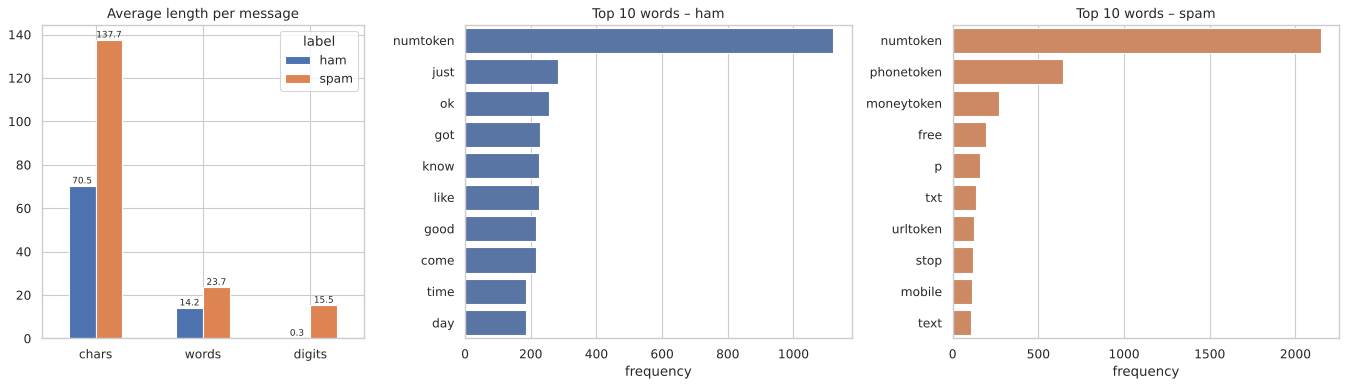

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.2, 1.2]})
gs = group_stats[["avg_char_length", "avg_word_count", "avg_digits"]].T
gs.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0)
axes[0].set_title("Average length per message"); axes[0].set_xticklabels(["chars", "words", "digits"])
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.1f", fontsize=8)
for ax, lab, color in [(axes[1], "ham", "#4C72B0"), (axes[2], "spam", "#DD8452")]:
    w, c = zip(*top10[lab])
    sns.barplot(x=list(c), y=list(w), ax=ax, color=color)
    ax.set_title(f"Top 10 words – {lab}"); ax.set_xlabel("frequency"); ax.set_ylabel("")
plt.tight_layout(); save_fig(fig, "group_comparison_spam_vs_ham.png"); plt.show()

In [23]:
# Optional word clouds (wordcloud is installed from requirements.txt inside the Docker image)
try:
    from wordcloud import WordCloud
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, lab, cmap in [(axes[0], "ham", "Blues"), (axes[1], "spam", "Oranges")]:
        text = " ".join(" ".join(ts) for ts in df.loc[df["label"] == lab, "tokens_nostop"])
        wc = WordCloud(width=700, height=400, background_color="white", colormap=cmap,
                       random_state=RANDOM_STATE, collocations=False).generate(text)
        ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"{lab.upper()} word cloud")
    plt.tight_layout(); save_fig(fig, "wordclouds_spam_vs_ham.png"); plt.show()
except ImportError:
    print("wordcloud not installed - skipping (install it with: pip install wordcloud)")

wordcloud not installed - skipping (install it with: pip install wordcloud)


In [24]:
# Save the cleaned dataset (original text kept, cleaned text and engineered features added)
export_cols = ["label", "label_num", "message", "cleaned_text", "token_count", "length_bin",
               "char_count", "word_count", "unique_word_count", "avg_word_length", "digit_count",
               "uppercase_ratio", "punctuation_count", "exclamation_count", "has_url", "has_long_number"] + norm_cols
df[export_cols].to_csv(OUTPUT_DIR / "cleaned_data.csv", index=False, encoding="utf-8")
print("Saved ->", (OUTPUT_DIR / "cleaned_data.csv").relative_to(ROOT), "| shape:", df[export_cols].shape)

Saved -> output/cleaned_data.csv | shape: (5171, 24)


### 5.5 Written insights
Each insight follows **Observation → Evidence → Interpretation**. Numbers come from the outputs above.


**Insight 1: Spam is about twice as long as ham and fills the SMS limit.**
*Observation:* spam messages are much longer. *Evidence:* average 137.7 vs 70.5 characters and 23.7 vs 14.2 words; 39.2 % of messages in the 101–160 character bin are spam, against only 0.9 % of messages up to 50 characters. *Interpretation:* commercial senders pay per message, so they pack an offer, a price and a call to action into the full 160 characters. Short texts are almost always personal, which makes length a useful (though not sufficient) signal.

**Insight 2: Long numbers are the fingerprint of spam.**
*Observation:* digits, especially phone numbers and short codes, are concentrated in spam. *Evidence:* 15.5 digits per spam message vs 0.3 per ham message; 76.7 % of spam contains a number of 5 or more digits vs 0.07 % of ham; `phonetoken` appears 644 times in spam and only 3 times in ham; `digit_count` has r = 0.84 with the label. *Interpretation:* spam asks the reader to call or text a premium‑rate number. This is why replacing numbers by tokens was worthwhile, and why `phonetoken` is the strongest spam feature of the classifier.

**Insight 3: Stop words dominate raw frequencies, and digits are "words" in SMS.**
*Observation:* before stop‑word removal, the top‑20 list is mostly function words. *Evidence:* stop words make up 82 % of the top‑20 occurrences (`i`, `to`, `you`, `a`, `the`, `u`…). After removal, `numtoken` is still first **in both classes** (ham 1,121, spam 2,148). *Interpretation:* in texting slang digits replace words ("2" = to, "4" = for, "gr8"), so a number in ham is often a word, while in spam it is a price. The number token needs care. It was kept for classification but treated as a stop word for clustering.

**Insight 4: The two classes use different vocabularies of intent.**
*Observation:* spam vocabulary is commercial and imperative; ham vocabulary is conversational. *Evidence:* spam top‑10 includes `moneytoken` (271), `free` (197), `txt`, `urltoken`, `stop`, `mobile`, `text`; elsewhere in the spam vocabulary `claim`, `prize`, `cash` and `reply` are frequent. Ham top‑10 is `just`, `ok`, `got`, `know`, `like`, `good`, `come`, `time`, `day`. *Interpretation:* the words alone reveal the sender's goal (sell vs chat). This explains why a simple bag‑of‑words TF‑IDF model reaches over 98 % accuracy and why K‑Means finds a "promotional" cluster without seeing labels.

**Insight 5: Spam relies on links and urgency.**
*Observation:* URLs and exclamation marks are much more common in spam. *Evidence:* 17.8 % of spam contains a URL vs 0.22 % of ham; spam averages 0.70 exclamation marks per message vs 0.18 for ham; typical words include "URGENT!", "WINNER!!", "claim". *Interpretation:* spam tries to push the reader into acting immediately (click, call, claim), a classic social‑engineering pattern that filters and users can watch for.

**Insight 6: Duplicates and regional slang reflect how the corpus was collected.**
*Observation:* the data contains repeated templates and heavy regional slang. *Evidence:* 403 exact duplicates (7.2 % of rows), including 94 spam copies (12.6 % of spam) and canned replies such as "Sorry, I'll call later" (30 times). Ham contains Singlish slang that never or almost never appears in spam (`lor` 159 times in ham vs 0 in spam, `dun` 55 vs 0, `liao` 37 vs 0), consistent with the dataset README (3,375 ham messages come from the NUS Singapore corpus, spam from a UK forum). *Interpretation:* duplicates had to be removed to avoid inflated counts and train/test leakage. The ham and spam come from **different populations**, so part of what the model learns is "Singapore student chat vs UK marketing", which may not generalise to other countries or modern spam.


## 6. Machine Learning
### 6.1 Supervised text classification (target: `label_num`, spam = 1 = positive class)

* **Split:** 80 % train / 20 % test, **stratified** on the label so both sets keep ≈12.6 % spam.
* **Features:** TF‑IDF on `cleaned_text` (fitted on the training set only, inside a `Pipeline`, so the test set never leaks into the vocabulary or IDF weights).
* **Models:** (A) Multinomial Naive Bayes, (B) Logistic Regression with `class_weight="balanced"`, and **(C, bonus)** Logistic Regression whose n‑gram range, `min_df` and regularisation `C` are chosen by a grid search (5‑fold CV, optimised for F1).

In [25]:
X = df["cleaned_text"]
y = df["label_num"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])
display(pd.DataFrame({"train % spam": [100 * y_train.mean()], "test % spam": [100 * y_test.mean()]}).round(2))

Train: 4136 | Test: 1035


,train % spam,test % spam
0,12.62,12.66


In [26]:
models = {
    "A. Multinomial NB (unigrams)": Pipeline([
        ("tfidf", TfidfVectorizer(min_df=2, sublinear_tf=True)),
        ("clf", MultinomialNB(alpha=1.0))]),
    "B. Logistic Regression (unigrams)": Pipeline([
        ("tfidf", TfidfVectorizer(min_df=2, sublinear_tf=True)),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))]),
}

# C. Bonus: n-grams + hyper-parameter tuning
grid = GridSearchCV(
    Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)),
              ("clf", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE))]),
    param_grid={"tfidf__ngram_range": [(1, 1), (1, 2)],
                "tfidf__min_df": [1, 2],
                "clf__C": [1, 10, 100]},
    scoring="f1", cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
grid.fit(X_train, y_train)
print("Best CV F1:", round(grid.best_score_, 4), "| best params:", grid.best_params_)
models["C. Tuned Logistic Regression (grid search) [bonus]"] = grid.best_estimator_

results, reports, cms, preds = [], {}, {}, {}
for name, model in models.items():
    if not name.startswith("C."):
        model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]
    preds[name] = y_pred
    cms[name] = confusion_matrix(y_test, y_pred)
    reports[name] = classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4)
    results.append({"model": name,
                    "accuracy": accuracy_score(y_test, y_pred),
                    "precision (spam)": precision_score(y_test, y_pred),
                    "recall (spam)": recall_score(y_test, y_pred),
                    "F1 (spam)": f1_score(y_test, y_pred),
                    "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
                    "ROC-AUC": roc_auc_score(y_test, y_score)})
results_df = pd.DataFrame(results).set_index("model").round(4)
display(results_df)
for name in models:
    print(f"\n=== {name} ===\n{reports[name]}")

Best CV F1: 0.9622 | best params: {'clf__C': 100, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}


,accuracy,precision (spam),recall (spam),F1 (spam),F1 (macro),ROC-AUC
model,,,,,,
A. Multinomial NB (unigrams),0.9807,0.9826,0.8626,0.9187,0.9539,0.9922
B. Logistic Regression (unigrams),0.9845,0.9389,0.9389,0.9389,0.9650,0.9940
C. Tuned Logistic Regression (grid search) [bonus],0.9865,0.9606,0.9313,0.9457,0.9690,0.9935



=== A. Multinomial NB (unigrams) ===
              precision    recall  f1-score   support

         ham     0.9804    0.9978    0.9890       904
        spam     0.9826    0.8626    0.9187       131

    accuracy                         0.9807      1035
   macro avg     0.9815    0.9302    0.9539      1035
weighted avg     0.9807    0.9807    0.9801      1035


=== B. Logistic Regression (unigrams) ===
              precision    recall  f1-score   support

         ham     0.9912    0.9912    0.9912       904
        spam     0.9389    0.9389    0.9389       131

    accuracy                         0.9845      1035
   macro avg     0.9650    0.9650    0.9650      1035
weighted avg     0.9845    0.9845    0.9845      1035


=== C. Tuned Logistic Regression (grid search) [bonus] ===
              precision    recall  f1-score   support

         ham     0.9901    0.9945    0.9923       904
        spam     0.9606    0.9313    0.9457       131

    accuracy                         0.98

Saved figure -> output/figures/confusion_matrices.png


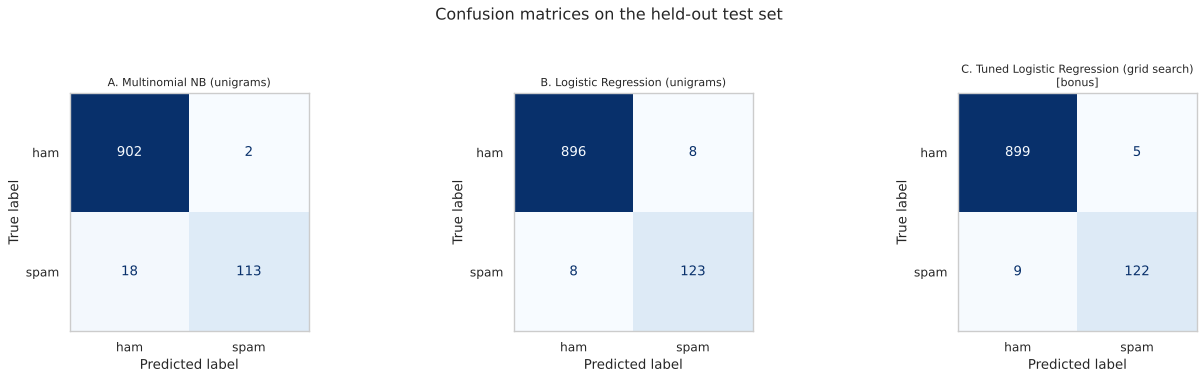

Saved figure -> output/figures/model_comparison.png


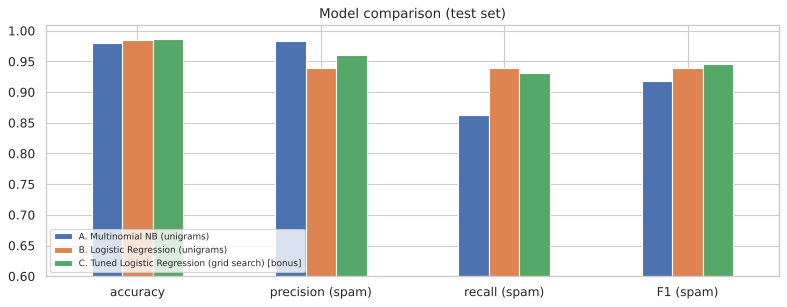

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (name, cm) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.grid(False)
    ax.set_title(name.replace(" [bonus]", "\n[bonus]"), fontsize=10)
plt.suptitle("Confusion matrices on the held-out test set", y=1.03)
plt.tight_layout(); save_fig(fig, "confusion_matrices.png"); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
results_df[["accuracy", "precision (spam)", "recall (spam)", "F1 (spam)"]].T.plot(kind="bar", ax=ax, rot=0)
ax.set_ylim(0.6, 1.01); ax.set_title("Model comparison (test set)"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); save_fig(fig, "model_comparison.png"); plt.show()

In [28]:
# Most informative words of the tuned logistic regression + misclassified examples
best_name = results_df["F1 (spam)"].idxmax()
best_model = models[best_name]
vec, clf = best_model.named_steps["tfidf"], best_model.named_steps["clf"]
feat = np.array(vec.get_feature_names_out()); coef = clf.coef_[0]
print("Best model by spam F1:", best_name)
display(pd.DataFrame({"strongest SPAM terms": feat[np.argsort(coef)[-15:][::-1]],
                      "strongest HAM terms": feat[np.argsort(coef)[:15]]}))

test_view = pd.DataFrame({"message": df.loc[X_test.index, "message"], "true": y_test, "pred": preds[best_name]})
print("False negatives (spam predicted as ham):")
display(test_view[(test_view.true == 1) & (test_view.pred == 0)].head(5))
print("False positives (ham predicted as spam):")
display(test_view[(test_view.true == 0) & (test_view.pred == 1)].head(5))

Best model by spam F1: C. Tuned Logistic Regression (grid search) [bonus]


,strongest SPAM terms,strongest HAM terms
0,phonetoken,my
1,urltoken,me
2,moneytoken,at
3,text,ok
4,txt,list
5,reply,hey
6,arsenal,added
7,free,place
8,won,then
9,numtoken,got


False negatives (spam predicted as ham):


,message,true,pred
4499,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,1,0
2642,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner,1,0
3332,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!",1,0
1813,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,1,0
2303,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs),1,0


False positives (ham predicted as spam):


,message,true,pred
487,Are you free now?can i call now?,0,1
1620,Glad to see your reply.,0,1
4416,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &lt;#&gt;,0,1
1262,Your daily text from me – a favour this time,0,1
3522,"Plz note: if anyone calling from a mobile Co. &amp; asks u to type # &lt;#&gt; or # &lt;#&gt; . Do not do so. Disconnect the call,coz it iz an attempt of 'terrorist' to make use of the sim card no. Itz confirmd by nokia n motorola n has been verified by CNN IBN.",0,1


In [29]:
# Save supervised results
with open(OUTPUT_DIR / "model_metrics.txt", "w", encoding="utf-8") as f:
    f.write("CSCI461 Assignment 1 - Supervised SMS spam classification\n")
    f.write("=" * 66 + "\n")
    f.write(f"Dataset: SMS Spam Collection, {len(df)} messages after removing duplicates\n")
    f.write(f"Split  : 80/20 stratified (train={len(X_train)}, test={len(X_test)}), random_state={RANDOM_STATE}\n")
    f.write("Features: TF-IDF on cleaned_text (fitted on training data only)\n")
    f.write("Positive class: spam (1)\n\n")
    f.write("Summary on test set\n-------------------\n")
    f.write(results_df.to_markdown() + "\n\n")
    f.write(f"Grid search (bonus) best params: {grid.best_params_} | best 5-fold CV F1 = {grid.best_score_:.4f}\n\n")
    for name in models:
        tn, fp, fn, tp = cms[name].ravel()
        f.write(f"=== {name} ===\n{reports[name]}\n")
        f.write(f"Confusion matrix [rows=true, cols=pred | ham, spam]:\n{cms[name]}\n")
        f.write(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}\n\n")
    f.write(f"Best model (spam F1): {best_name}\n\n")
    f.write('''Interpretation
--------------
- Baseline (always predict ham) = 87.3% accuracy, so precision/recall/F1 for the spam class are the key metrics.
- Naive Bayes: highest precision (0.98, 2 false positives) but lowest recall (0.86, 18 spam missed).
- Balanced Logistic Regression: precision = recall = 0.94; better balance (spam F1 0.939).
- Tuned Logistic Regression (bonus grid search): best accuracy 98.65% and spam F1 0.946 (9 FN, 5 FP).
  The grid chose unigrams, min_df=2, C=100; bigrams did not improve 5-fold CV F1.
- Strongest spam terms: phonetoken, urltoken, moneytoken, text, txt, reply, free, won.
- Missed spam is mostly promotional text without numbers/links; false alarms are ham using words like free/call/text.

Limitations
-----------
1. Imbalanced data and only 131 spam messages in the test set: each error changes recall by ~0.8 points; single split.
2. Old (2000s) and source-specific data (UK spam vs Singapore ham): likely concept drift on modern spam.
3. Bag-of-words ignores word order and is vulnerable to obfuscated or conversational spam.''' + "\n")
print("Saved ->", (OUTPUT_DIR / "model_metrics.txt").relative_to(ROOT))

Saved -> output/model_metrics.txt


**Interpretation**

* **All three models are far above the baseline.** Predicting "ham" for every message would already give 87.3 % accuracy, so accuracy alone is misleading on this imbalanced data. Precision, recall and F1 **for the spam class** are the meaningful metrics.
* **A. Naive Bayes** is the most *precise* (0.98: only 2 legitimate messages flagged), but it misses about 14 % of spam (recall 0.86, 18 false negatives). With a prior of 87 % ham and short texts, NB plays it safe.
* **B. Logistic Regression with balanced class weights** trades a little precision for much better recall (0.94/0.94, 8 FN and 8 FP), raising spam F1 from 0.919 to 0.939.
* **C. Tuned Logistic Regression (bonus)** has the best accuracy (98.65 %) and spam F1 (0.946), with 9 FN and 5 FP. The grid search picked **unigrams, `min_df=2`, C = 100**: adding bigrams did **not** improve the cross‑validated F1, so single words already capture the signal.
* **Which errors matter?** A false positive (a real message sent to the spam folder) usually costs the user more than a missed spam. If that is the priority, model A's high precision is attractive; if catching spam matters more, model C or B is better. The decision threshold could also be tuned.
* **What the model learned:** the strongest spam terms are `phonetoken`, `urltoken`, `moneytoken`, `text`, `txt`, `reply`, `free`, `won`, matching the insights in Section 5. **Errors:** missed spam is mostly promotional or adult text *without* numbers or links, which reads like normal chat (Burger King promotion, club tickets). False alarms are ham messages that use spam‑like words ("Are you free now? can I call now?").

**Limitations**
1. **Class imbalance and a small test set:** only 131 spam messages in the test set, so each mistake moves recall by about 0.8 points. Results come from one split; cross‑validated scores would be more reliable.
2. **Dataset age and origin:** the messages are from the 2000s (ringtones, Nokia, £ prizes) and from different sources for ham and spam, so performance on today's spam (phishing links, WhatsApp scams, other languages) is likely lower (concept drift).
3. **Bag‑of‑words** ignores word order and context, and can be fooled by obfuscation ("fr33", "c@ll") or by spam that imitates normal conversation.
